
Standard curve equation:
Peak area = 6.4189 × melatonin_nM + 156.4156
R² = 0.99714


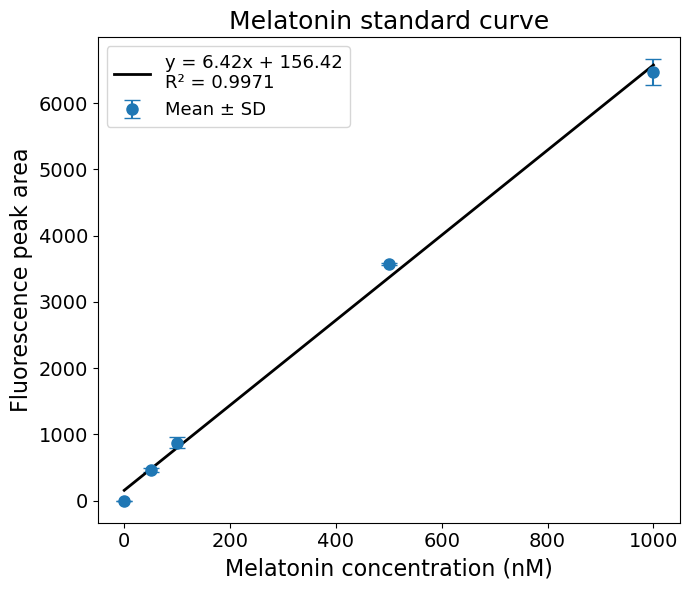

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress

# 1. Enter standard curve data
standard_data = pd.DataFrame({
    "melatonin_nM": [0, 50, 100, 500, 1000],
    "rep1": [0.000, 488.384, 783.236, 3588.379, 6640.918],
    "rep2": [0.000, 435.811, 906.884, 3569.650, 6499.209],
    "rep3": [0.000, 460.356, 933.935, 3555.833, 6257.005]
})

# 2. Calculate mean and SD
standard_data["mean_area"] = standard_data[["rep1", "rep2", "rep3"]].mean(axis=1)
standard_data["sd_area"] = standard_data[["rep1", "rep2", "rep3"]].std(axis=1)

# 3. Linear regression
x = standard_data["melatonin_nM"].values
y = standard_data["mean_area"].values

slope, intercept, r_value, p_value, std_err = linregress(x, y)

print("\nStandard curve equation:")
print(f"Peak area = {slope:.4f} × melatonin_nM + {intercept:.4f}")
print(f"R² = {r_value**2:.5f}")


# 4. Plot and save standard curve
x_fit = np.linspace(0, 1000, 300)
y_fit = slope * x_fit + intercept

plt.figure(figsize=(7, 6))

plt.errorbar(
    standard_data["melatonin_nM"],
    standard_data["mean_area"],
    yerr=standard_data["sd_area"],
    fmt="o",
    capsize=6,
    markersize=8,
    label="Mean ± SD"
)

plt.plot(
    x_fit,
    y_fit,
    color="black",
    linewidth=2,
    label=f"y = {slope:.2f}x + {intercept:.2f}\nR² = {r_value**2:.4f}"
)

plt.xlabel("Melatonin concentration (nM)", fontsize=16)
plt.ylabel("Fluorescence peak area", fontsize=16)
plt.title("Melatonin standard curve", fontsize=18)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)

plt.legend(fontsize=13, frameon=True)

plt.tight_layout()

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/melatonin_standard_curve_large_font.png",
    dpi=300
)

plt.savefig(
    "/home/nrz989/Documents/ASMT dynamic analysis/melatonin_standard_curve_large_font.pdf"
)

plt.show()